Fourier transforms of a rectangular pulse and of Gaussians (Shiyi (Amy) Qin and Victor Z, UW-Madison, 2020).
Filters $g$ (`g`) are the pdf of $\mathcal{U}(4,6)$ and of $\mathcal{N}(5,\sigma^2)$ with $\sigma=0.4$ and 1;
we plot the one-sided magnitude $|\hat{g}(\omega)|$.

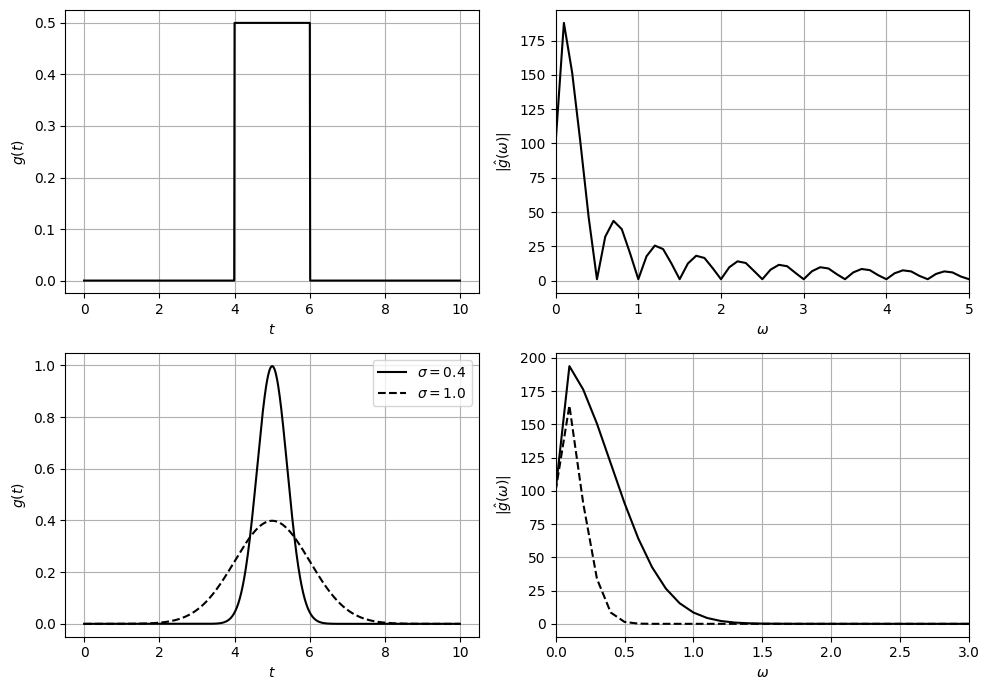

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, norm

L, Fs = 1000, 100
t = np.arange(L) / Fs
omega = Fs * np.arange(L // 2 + 1) / L

def power(z):
    m = np.abs(np.fft.fft(z)[:L // 2 + 1])
    m[1:-1] *= 2
    return m

fig, axs = plt.subplots(2, 2, figsize=(10, 7))
g = uniform.pdf(t, 4, 2)
axs[0, 0].plot(t, g, 'k'); axs[0, 1].plot(omega, power(g), 'k'); axs[0, 1].set_xlim(0, 5)
for sigma, style in ((0.4, 'k-'), (1.0, 'k--')):
    g = norm.pdf(t, 5, sigma)
    axs[1, 0].plot(t, g, style, label=rf'$\sigma={sigma}$')
    axs[1, 1].plot(omega, power(g), style)
axs[1, 1].set_xlim(0, 3)
axs[1, 0].legend()
for ax in axs[:, 0]:
    ax.set_xlabel('$t$'); ax.set_ylabel('$g(t)$')
for ax in axs[:, 1]:
    ax.set_xlabel(r'$\omega$'); ax.set_ylabel(r'$|\hat{g}(\omega)|$')
for ax in axs.ravel():
    ax.grid(True)
plt.tight_layout()
plt.show()